In [1]:
!pip install -q transformers==4.49.0 peft trl bitsandbytes accelerate qwen-vl-utils

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 52.2 MB/s eta 0:00:00


In [2]:
!nvidia-smi --query-gpu=memory.used,memory.free --format=csv

memory.used [MiB], memory.free [MiB]
0 MiB, 14913 MiB
0 MiB, 14913 MiB


In [3]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="Qwen/Qwen2-VL-2B-Instruct",
    local_dir="/kaggle/working/qwen2vl-2b",
    ignore_patterns=["*.pt", "*.bin"],
)
print("✅ Done")

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

README.md: 0.00B [00:00, ?B/s]

.gitattributes: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/429M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

✅ Done


In [4]:
import json, os
from PIL import Image
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained("/kaggle/working/qwen2vl-2b")
BASE = "/kaggle/input/datasets/ccaglaa/pai2d-train-dataset-v4"

with open(f"{BASE}/manifests/formatted/train_composed.jsonl") as f:
    rec = json.loads(f.readline())
rec["image"] = f"{BASE}/images/{rec['split']}/composite/{os.path.basename(rec['image'])}"

label           = rec["label"]
label_token_ids = processor.tokenizer.encode(label, add_special_tokens=False)

image    = Image.open(rec["image"]).convert("RGB")
messages = [
    {"role": "system", "content": "Reply with ONLY the operation name."},
    {"role": "user",   "content": [
        {"type": "image", "image": image},
        {"type": "text",  "text":  "What operation was applied?"},
    ]},
    {"role": "assistant", "content": label},
]
text      = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
inputs    = processor(text=[text], images=[image], return_tensors="pt", padding=True)
input_ids = inputs["input_ids"].squeeze(0).tolist()

found_at = None
for i in range(len(input_ids) - len(label_token_ids), -1, -1):
    if input_ids[i:i+len(label_token_ids)] == label_token_ids:
        found_at = i
        break

print(f"Label        : {label}")
print(f"Tokens       : {label_token_ids}")
print(f"Found at pos : {found_at}")
print(f"Decoded back : {processor.tokenizer.decode(input_ids[found_at:found_at+len(label_token_ids)])}")
print(f"Seq length   : {len(input_ids)}")
print(f"✅ Masking OK" if found_at is not None else "❌ Label NOT found")

2026-05-11 08:23:09.154253: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778487789.543006      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778487789.660270      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778487790.648656      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778487790.648731      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778487790.648733      23 computation_placer.cc:177] computation placer alr

Label        : gaussian_blur
Tokens       : [6743, 15579, 13141, 324]
Found at pos : 539
Decoded back : gaussian_blur
Seq length   : 545
✅ Masking OK


In [5]:
script = '''
import os, json, torch, warnings, logging

os.environ["TOKENIZERS_PARALLELISM"]    = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"]      = "3"
os.environ["TRANSFORMERS_VERBOSITY"]    = "error"
os.environ["DATASETS_VERBOSITY"]        = "error"
os.environ["TORCH_DISTRIBUTED_DEBUG"]   = "OFF"

warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("datasets").setLevel(logging.ERROR)
logging.getLogger("peft").setLevel(logging.ERROR)
logging.getLogger("torch.distributed").setLevel(logging.ERROR)

from PIL import Image
from torch.utils.data import Dataset
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig, TrainerCallback
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTConfig, SFTTrainer
from torch.nn.utils.rnn import pad_sequence
import torch.distributed as dist

BASE       = "/kaggle/input/datasets/ccaglaa/pai2d-train-dataset-v4"
MODEL_DIR  = "/kaggle/working/qwen2vl-2b"
OUTPUT_DIR = "/kaggle/working/qwen2vl-v4-lora"

MIN_PIXELS = 64  * 28 * 28
MAX_PIXELS = 512 * 28 * 28

LABEL_SET_V3 = [
    "brightness_contrast", "colorize", "desaturate", "edge_detect",
    "flip_horizontal", "flip_vertical",
    "gaussian_blur", "hue_saturation", "invert", "posterize",
    "red_eye_removal", "rotation", "sharpen", "threshold",
]

SYSTEM_PROMPT = (
    "You are a GIMP image-editing analysis assistant. "
    "You will be shown a triptych image: "
    "the LEFT panel is the ORIGINAL image, "
    "the CENTER panel is the RESULT after exactly ONE GIMP operation was applied, "
    "and the RIGHT panel is an amplified pixel difference map. "
    "Your task is to identify that single operation. "
    "Reply with ONLY the operation name from the provided list — "
    "no explanation, no punctuation."
)

USER_TEMPLATE = (
    "The LEFT panel is BEFORE, the CENTER is AFTER, "
    "the RIGHT is the amplified difference (x15).\\n\\n"
    "Valid operations:\\n{label_list}\\n\\n"
    "What single GIMP operation was applied?"
)

def fix_path(record):
    fname = os.path.basename(record["image"])
    split = record["split"]
    record["image"] = f"{BASE}/images/{split}/composite/{fname}"
    return record

with open(f"{BASE}/manifests/formatted/train_composed.jsonl") as f:
    train_records = [fix_path(json.loads(l)) for l in f if l.strip()]
with open(f"{BASE}/manifests/formatted/val_composed.jsonl") as f:
    val_records = [fix_path(json.loads(l)) for l in f if l.strip()]

local_rank = int(os.environ.get("LOCAL_RANK", 0))

processor = AutoProcessor.from_pretrained(
    MODEL_DIR,
    min_pixels=MIN_PIXELS,
    max_pixels=MAX_PIXELS,
)

class AI2DDataset(Dataset):
    def __init__(self, records, processor, label_set):
        self.records   = records
        self.processor = processor
        self.label_set = label_set

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec        = self.records[idx]
        image      = Image.open(rec["image"]).convert("RGB")
        label_list = ", ".join(self.label_set)
        user_text  = USER_TEMPLATE.format(label_list=label_list)
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": [
                {"type": "image", "image": image},
                {"type": "text",  "text":  user_text},
            ]},
            {"role": "assistant", "content": rec["label"]},
        ]
        text   = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        inputs = processor(
            text=[text], images=[image], return_tensors="pt", padding=True,
            min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS,
        )
        item   = {k: v.squeeze(0) for k, v in inputs.items()}

        input_ids_list  = item["input_ids"].tolist()
        label_token_ids = processor.tokenizer.encode(rec["label"], add_special_tokens=False)
        n               = len(label_token_ids)

        labels = torch.full_like(item["input_ids"], -100)
        for i in range(len(input_ids_list) - n, -1, -1):
            if input_ids_list[i:i+n] == label_token_ids:
                labels[i:i+n] = item["input_ids"][i:i+n]
                break

        item["labels"] = labels
        return item

def collate_fn(batch):
    input_ids      = pad_sequence([b["input_ids"]      for b in batch], batch_first=True, padding_value=0)
    attention_mask = pad_sequence([b["attention_mask"] for b in batch], batch_first=True, padding_value=0)
    labels         = pad_sequence([b["labels"]         for b in batch], batch_first=True, padding_value=-100)
    out = {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}
    if "pixel_values" in batch[0]:
        try:
            out["pixel_values"] = torch.stack([b["pixel_values"] for b in batch])
        except RuntimeError:
            out["pixel_values"] = batch[0]["pixel_values"].unsqueeze(0).expand(len(batch), -1, -1)
    if "image_grid_thw" in batch[0]:
        out["image_grid_thw"] = torch.stack([b["image_grid_thw"] for b in batch])
    return out

class ProgressCallback(TrainerCallback):
    def on_log(self, args, state, control, logs=None, **kwargs):
        if state.is_local_process_zero and logs:
            loss = logs.get("loss", None)
            loss_str = f"{loss:.4f}" if isinstance(loss, float) else "N/A"
            print(
                f"  step {state.global_step}/{state.max_steps} | "
                f"loss={loss_str} | "
                f"lr={logs.get('learning_rate', 0):.2e} | "
                f"epoch={logs.get('epoch', 0):.2f}",
                flush=True
            )

    def on_epoch_end(self, args, state, control, **kwargs):
        if state.is_local_process_zero:
            print(f"\\n{'='*60}", flush=True)
            print(f"  Epoch {int(state.epoch)} complete", flush=True)
            print(f"{'='*60}\\n", flush=True)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_DIR,
    quantization_config=bnb_config,
    device_map={"": local_rank},
    torch_dtype=torch.float16,
)
model.config.use_cache = False

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=64,
    lora_alpha=128,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)
model = get_peft_model(model, lora_config)

train_ds = AI2DDataset(train_records, processor, LABEL_SET_V3)
val_ds   = AI2DDataset(val_records,   processor, LABEL_SET_V3)

os.makedirs(OUTPUT_DIR, exist_ok=True)

sft_config = SFTConfig(
    output_dir=OUTPUT_DIR,
    num_train_epochs=8,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    gradient_checkpointing=False,
    optim="paged_adamw_8bit",
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.0,
    weight_decay=0.01,
    max_grad_norm=1.0,
    fp16=True,
    bf16=False,
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    dataloader_num_workers=0,
    remove_unused_columns=False,
    report_to="none",
    seed=42,
    dataset_text_field="label",
    dataset_kwargs={"skip_prepare_dataset": True},
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collate_fn,
)

trainer.add_callback(ProgressCallback())

if dist.is_initialized():
    print(f"Rank {dist.get_rank()} ready", flush=True)

trainer.train()
trainer.save_model(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)
print("✅ Training complete")
'''

with open("/kaggle/working/train_script.py", "w") as f:
    f.write(script)

print("✅ Script written")

✅ Script written


In [6]:
import os, subprocess

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"]   = "3"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["PYTORCH_ALLOC_CONF"]     = "expandable_segments:True"

result = subprocess.run(
    [
        "torchrun",
        "--nproc_per_node=2",
        "--master_port=29501",
        "/kaggle/working/train_script.py"
    ],
    capture_output=False,
)
print("Exit code:", result.returncode)

W0511 08:23:46.632000 604 torch/distributed/run.py:852] 
W0511 08:23:46.632000 604 torch/distributed/run.py:852] *****************************************
W0511 08:23:46.632000 604 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0511 08:23:46.632000 604 torch/distributed/run.py:852] *****************************************
E0000 00:00:1778487832.802091     610 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778487832.802253     611 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778487832.810293     610 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plug

Rank 0 ready


No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Rank 1 ready


[rank0]:[W511 08:24:50.626347971 reducer.cpp:1500] Warning: find_unused_parameters=True was specified in DDP constructor, but did not find any unused parameters in the forward pass. This flag results in an extra traversal of the autograd graph every iteration,  which can adversely affect performance. If your model indeed never has any unused parameters in the forward pass, consider turning this flag off. Note that this warning may be a false positive if your model has flow control causing later iterations to have unused parameters. (function operator())
[rank1]:[W511 08:24:50.644352062 reducer.cpp:1500] Warning: find_unused_parameters=True was specified in DDP constructor, but did not find any unused parameters in the forward pass. This flag results in an extra traversal of the autograd graph every iteration,  which can adversely affect performance. If your model indeed never has any unused parameters in the forward pass, consider turning this flag off. Note that this warning may be a 

{'loss': 1.4254, 'grad_norm': 5.211787223815918, 'learning_rate': 9.994907306529202e-05, 'num_tokens': 220935.0, 'mean_token_accuracy': 0.610571850836277, 'epoch': 0.11428571428571428}
  step 10/696 | loss=1.4254 | lr=9.99e-05 | epoch=0.11
{'loss': 1.2426, 'grad_norm': 3.0194084644317627, 'learning_rate': 9.979639600327522e-05, 'num_tokens': 441880.0, 'mean_token_accuracy': 0.6032421499490738, 'epoch': 0.22857142857142856}
  step 20/696 | loss=1.2426 | lr=9.98e-05 | epoch=0.23
{'loss': 1.1956, 'grad_norm': 3.1921041011810303, 'learning_rate': 9.954227982894034e-05, 'num_tokens': 662795.0, 'mean_token_accuracy': 0.6151917971670627, 'epoch': 0.34285714285714286}
  step 30/696 | loss=1.1956 | lr=9.95e-05 | epoch=0.34
{'loss': 1.1419, 'grad_norm': 3.9135239124298096, 'learning_rate': 9.918724219660013e-05, 'num_tokens': 883718.0, 'mean_token_accuracy': 0.6344343950971961, 'epoch': 0.45714285714285713}
  step 40/696 | loss=1.1419 | lr=9.92e-05 | epoch=0.46
{'loss': 1.0569, 'grad_norm': 2.63

[rank0]:[W511 15:40:01.217140086 ProcessGroupNCCL.cpp:1553] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


Exit code: 0


In [7]:
import shutil, os
os.makedirs("/kaggle/working/output", exist_ok=True)
shutil.copytree(
    "/kaggle/working/qwen2vl-v4-lora",
    "/kaggle/working/output/qwen2vl-v4-lora",
    dirs_exist_ok=True
)
print("✅ Copied to output folder")


✅ Copied to output folder


In [8]:
import os, json, torch, warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

from PIL import Image
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import PeftModel

BASE       = "/kaggle/input/datasets/ccaglaa/pai2d-train-dataset-v4"
MODEL_DIR  = "/kaggle/working/qwen2vl-2b"
LORA_DIR   = "/kaggle/working/qwen2vl-v4-lora"

MIN_PIXELS = 64  * 28 * 28
MAX_PIXELS = 512 * 28 * 28

LABEL_SET_V3 = [
    "brightness_contrast", "colorize", "desaturate", "edge_detect",
    "flip_horizontal", "flip_vertical",
    "gaussian_blur", "hue_saturation", "invert", "posterize",
    "red_eye_removal", "rotation", "sharpen", "threshold",
]

SYSTEM_PROMPT = (
    "You are a GIMP image-editing analysis assistant. "
    "You will be shown a triptych image: "
    "the LEFT panel is the ORIGINAL image, "
    "the CENTER panel is the RESULT after exactly ONE GIMP operation was applied, "
    "and the RIGHT panel is an amplified pixel difference map. "
    "Your task is to identify that single operation. "
    "Reply with ONLY the operation name from the provided list — "
    "no explanation, no punctuation."
)

USER_TEMPLATE = (
    "The LEFT panel is BEFORE, the CENTER is AFTER, "
    "the RIGHT is the amplified difference (x15).\n\n"
    "Valid operations:\n{label_list}\n\n"
    "What single GIMP operation was applied?"
)

def fix_path(r):
    fname = os.path.basename(r["image"])
    r["image"] = f"{BASE}/images/{r['split']}/composite/{fname}"
    return r

with open(f"{BASE}/manifests/formatted/val_composed.jsonl") as f:
    val_records = [fix_path(json.loads(l)) for l in f if l.strip()]

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

base_model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_DIR,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.float16,
)
model = PeftModel.from_pretrained(base_model, LORA_DIR)
model.eval()

processor = AutoProcessor.from_pretrained(
    LORA_DIR,
    min_pixels=MIN_PIXELS,
    max_pixels=MAX_PIXELS,
)

print(f"✅ Model loaded")
print(f"   Val samples: {len(val_records)}")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

✅ Model loaded
   Val samples: 560


In [9]:
from tqdm import tqdm

def predict(rec):
    try:
        image      = Image.open(rec["image"]).convert("RGB")
        label_list = ", ".join(LABEL_SET_V3)
        user_text  = USER_TEMPLATE.format(label_list=label_list)
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user",   "content": [
                {"type": "image", "image": image},
                {"type": "text",  "text":  user_text},
            ]},
        ]
        text   = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(
            text=[text], images=[image], return_tensors="pt",
            min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS,
        ).to("cuda")

        with torch.no_grad():
            out = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                temperature=None,
                top_p=None,
            )
        decoded = processor.batch_decode(
            out[:, inputs.input_ids.shape[1]:],
            skip_special_tokens=True)[0].strip().lower()

        pred = decoded if decoded in LABEL_SET_V3 else "unknown"
        return pred
    except Exception:
        return "unknown"

print("Running evaluation on val set...")
preds, labels = [], []
for rec in tqdm(val_records):
    pred = predict(rec)
    preds.append(pred)
    labels.append(rec["label"])

acc = sum(p == l for p, l in zip(preds, labels)) / len(labels)
print(f"\n✅ Evaluation complete")
print(f"   Accuracy : {acc*100:.1f}%")
print(f"   Samples  : {len(labels)}")
print(f"   Unknown  : {preds.count('unknown')}")

Running evaluation on val set...


100%|██████████| 560/560 [12:43<00:00,  1.36s/it]


✅ Evaluation complete
   Accuracy : 58.6%
   Samples  : 560
   Unknown  : 0


Macro F1 : 0.5825

                     precision    recall  f1-score   support

Brightness-Contrast       0.54      0.35      0.42        40
           Colorize       0.71      0.62      0.67        40
         Desaturate       0.75      0.60      0.67        40
        Edge Detect       0.95      0.88      0.91        40
    Flip Horizontal       0.34      0.50      0.40        40
      Flip Vertical       0.78      0.17      0.29        40
      Gaussian Blur       0.57      0.68      0.62        40
     Hue-Saturation       0.42      0.47      0.45        40
             Invert       0.76      0.72      0.74        40
          Posterize       0.67      0.20      0.31        40
    Red Eye Removal       0.95      0.93      0.94        40
           Rotation       0.28      0.65      0.39        40
            Sharpen       0.73      0.60      0.66        40
          Threshold       0.60      0.82      0.69        40

           accuracy                           0.59       560
   

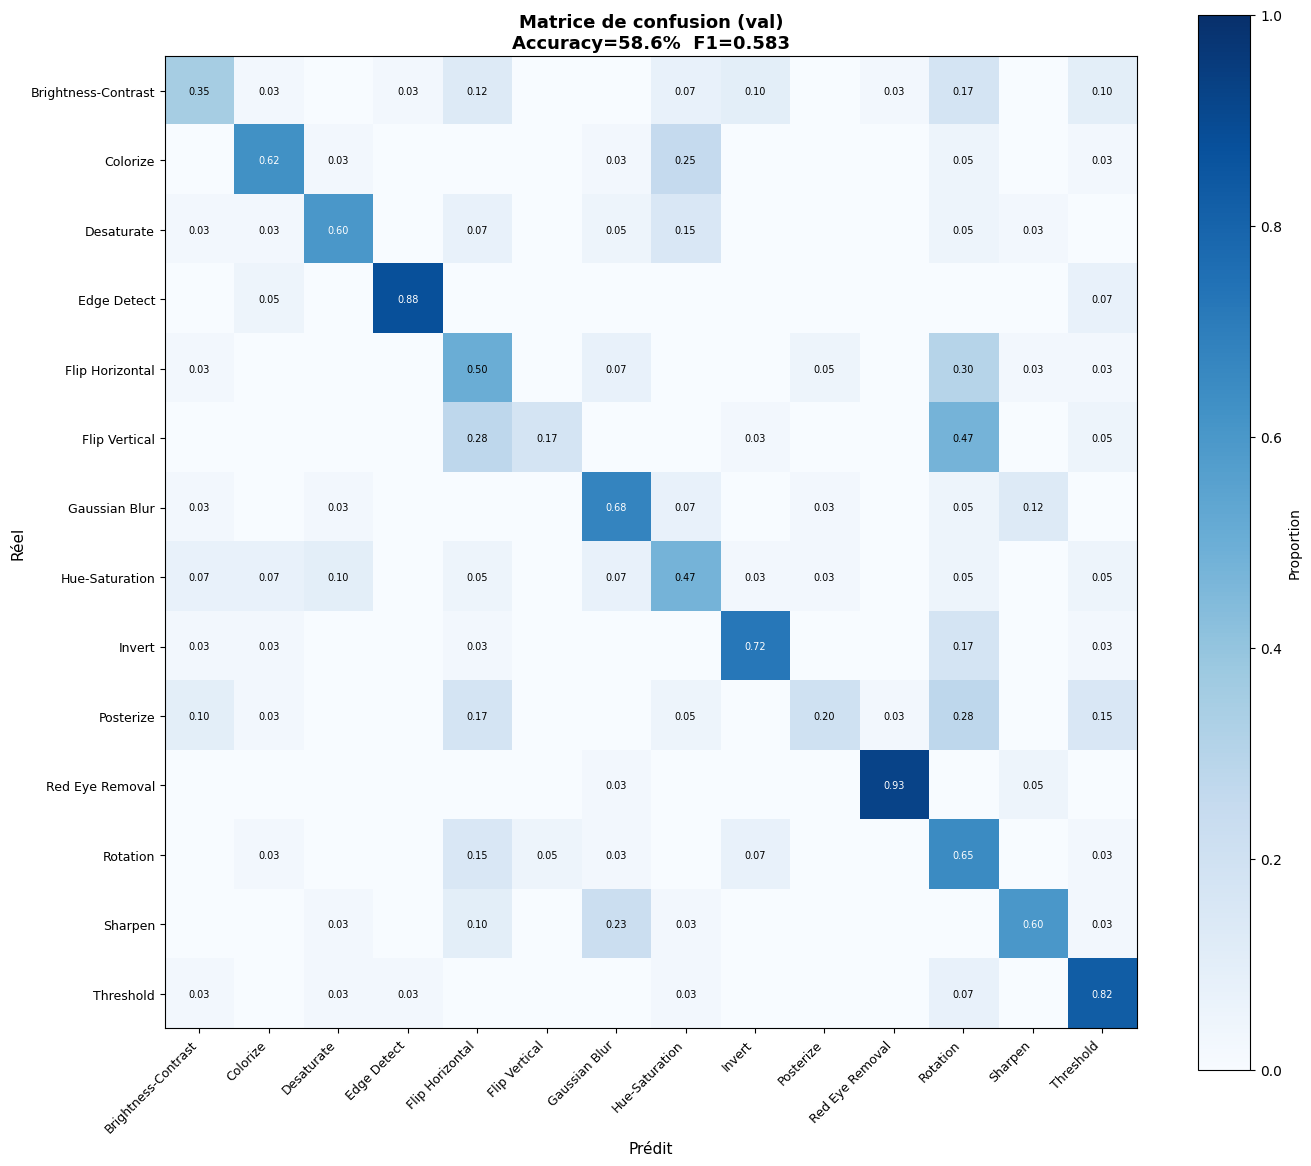

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score

DISPLAY_NAMES = {
    "gaussian_blur":       "Gaussian Blur",
    "sharpen":             "Sharpen",
    "brightness_contrast": "Brightness-Contrast",
    "hue_saturation":      "Hue-Saturation",
    "desaturate":          "Desaturate",
    "invert":              "Invert",
    "threshold":           "Threshold",
    "posterize":           "Posterize",
    "colorize":            "Colorize",
    "edge_detect":         "Edge Detect",
    "red_eye_removal":     "Red Eye Removal",
    "rotation":            "Rotation",
    "flip_horizontal":     "Flip Horizontal",
    "flip_vertical":       "Flip Vertical",
}

macro_f1 = f1_score(labels, preds, labels=LABEL_SET_V3, average="macro", zero_division=0)
report   = classification_report(labels, preds, labels=LABEL_SET_V3,
                                  target_names=[DISPLAY_NAMES[c] for c in LABEL_SET_V3],
                                  zero_division=0)
print(f"Macro F1 : {macro_f1:.4f}")
print(f"\n{report}")

cm      = confusion_matrix(labels, preds, labels=LABEL_SET_V3)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="Proportion")
ax.set_xticks(range(len(LABEL_SET_V3)))
ax.set_yticks(range(len(LABEL_SET_V3)))
ax.set_xticklabels([DISPLAY_NAMES[c] for c in LABEL_SET_V3], rotation=45, ha="right", fontsize=9)
ax.set_yticklabels([DISPLAY_NAMES[c] for c in LABEL_SET_V3], fontsize=9)
ax.set_xlabel("Prédit", fontsize=11)
ax.set_ylabel("Réel", fontsize=11)
ax.set_title(f"Matrice de confusion (val)\nAccuracy={acc*100:.1f}%  F1={macro_f1:.3f}",
             fontweight="bold", fontsize=13)
for i in range(len(LABEL_SET_V3)):
    for j in range(len(LABEL_SET_V3)):
        val = cm_norm[i, j]
        if val > 0.01:
            ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if val > 0.5 else "black")
plt.tight_layout()
plt.savefig("/kaggle/working/output/confusion_matrix.jpeg", bbox_inches="tight", dpi=150)
plt.show()


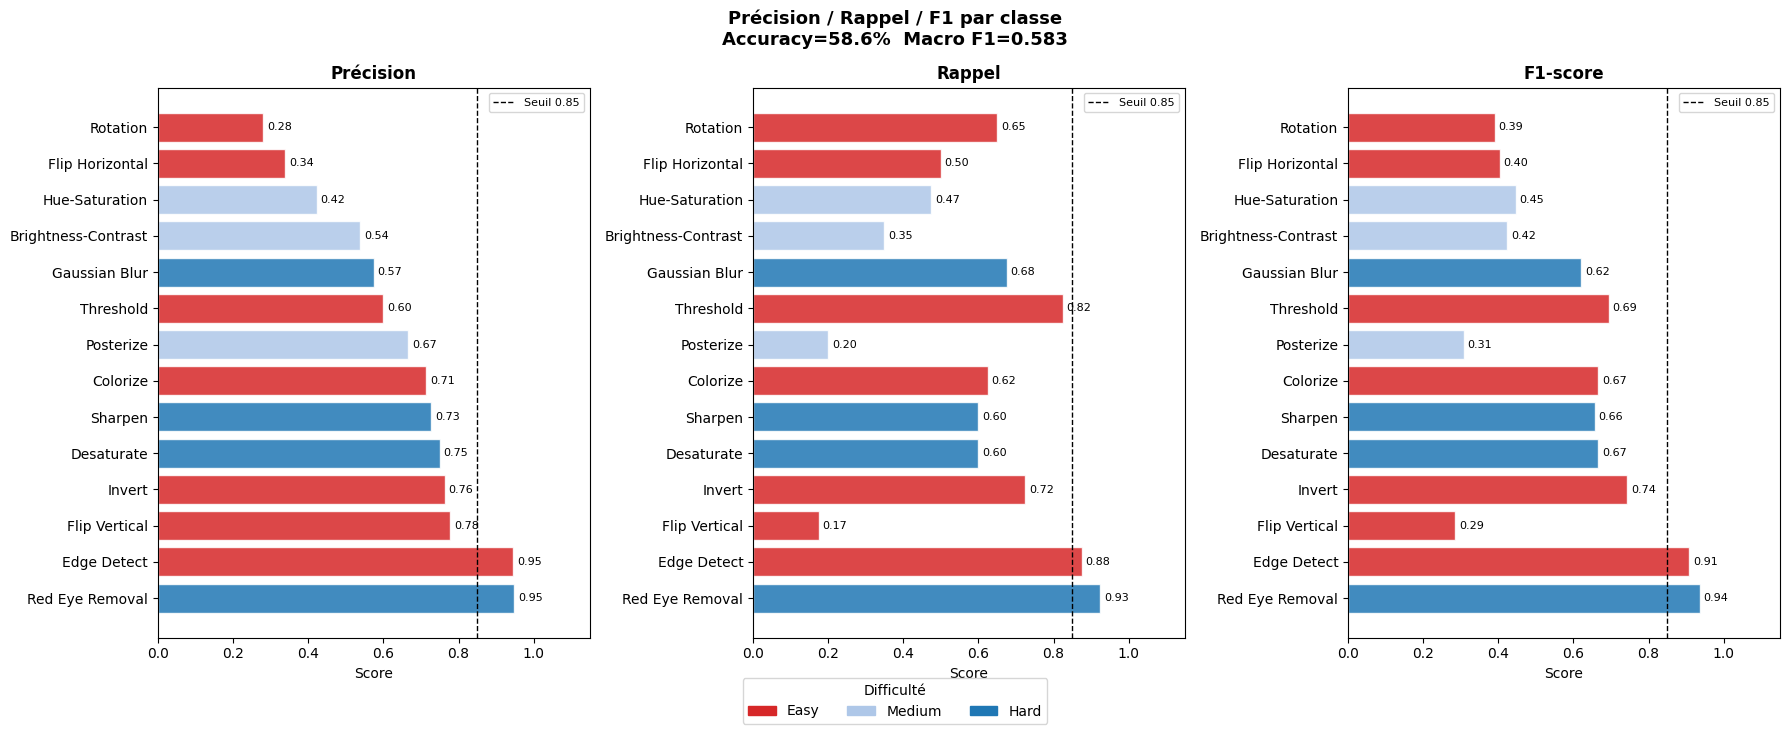

In [11]:
from sklearn.metrics import precision_score, recall_score
import matplotlib.patches as mpatches

precisions = precision_score(labels, preds, labels=LABEL_SET_V3, average=None, zero_division=0)
recalls    = recall_score(   labels, preds, labels=LABEL_SET_V3, average=None, zero_division=0)
from sklearn.metrics import f1_score as sklearn_f1
f1s        = sklearn_f1(     labels, preds, labels=LABEL_SET_V3, average=None, zero_division=0)

DIFFICULTY = {
    "invert":              "easy",
    "edge_detect":         "easy",
    "threshold":           "easy",
    "rotation":            "easy",
    "flip_horizontal":     "easy",
    "flip_vertical":       "easy",
    "colorize":            "easy",
    "brightness_contrast": "medium",
    "hue_saturation":      "medium",
    "posterize":           "medium",
    "desaturate":          "hard",
    "gaussian_blur":       "hard",
    "sharpen":             "hard",
    "red_eye_removal":     "hard",
}
TIER_COLORS = {"easy": "#d62728", "medium": "#aec7e8", "hard": "#1f77b4"}

sorted_idx = np.argsort(precisions)[::-1]
sorted_cls = [LABEL_SET_V3[i] for i in sorted_idx]
sorted_p   = [precisions[i]   for i in sorted_idx]
sorted_r   = [recalls[i]      for i in sorted_idx]
sorted_f   = [f1s[i]          for i in sorted_idx]
colors     = [TIER_COLORS[DIFFICULTY[c]] for c in sorted_cls]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, vals, title in [
    (axes[0], sorted_p, "Précision"),
    (axes[1], sorted_r, "Rappel"),
    (axes[2], sorted_f, "F1-score"),
]:
    bars = ax.barh([DISPLAY_NAMES[c] for c in sorted_cls], vals,
                    color=colors, alpha=0.85, edgecolor="white")
    ax.axvline(0.85, color="black", linestyle="--", linewidth=1, label="Seuil 0.85")
    for bar, v in zip(bars, vals):
        ax.text(v + 0.01, bar.get_y() + bar.get_height()/2,
                f"{v:.2f}", va="center", fontsize=8)
    ax.set_xlim(0, 1.15)
    ax.set_title(title, fontweight="bold", fontsize=12)
    ax.set_xlabel("Score")
    ax.legend(fontsize=8)

patches = [mpatches.Patch(color=c, label=l.capitalize())
           for l, c in TIER_COLORS.items()]
fig.legend(handles=patches, loc="lower center", ncol=3,
           title="Difficulté", bbox_to_anchor=(0.5, -0.05), fontsize=10)

plt.suptitle(f"Précision / Rappel / F1 par classe\n"
             f"Accuracy={acc*100:.1f}%  Macro F1={macro_f1:.3f}",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/output/per_class_metrics.jpeg", bbox_inches="tight", dpi=150)
plt.show()


Total errors: 232 / 560

Top 10 confusion pairs:
  Flip Vertical             -> Rotation                   (19x)
  Flip Horizontal           -> Rotation                   (12x)
  Posterize                 -> Rotation                   (11x)
  Flip Vertical             -> Flip Horizontal            (11x)
  Colorize                  -> Hue-Saturation             (10x)
  Sharpen                   -> Gaussian Blur              (9x)
  Brightness-Contrast       -> Rotation                   (7x)
  Invert                    -> Rotation                   (7x)
  Posterize                 -> Flip Horizontal            (7x)
  Desaturate                -> Hue-Saturation             (6x)


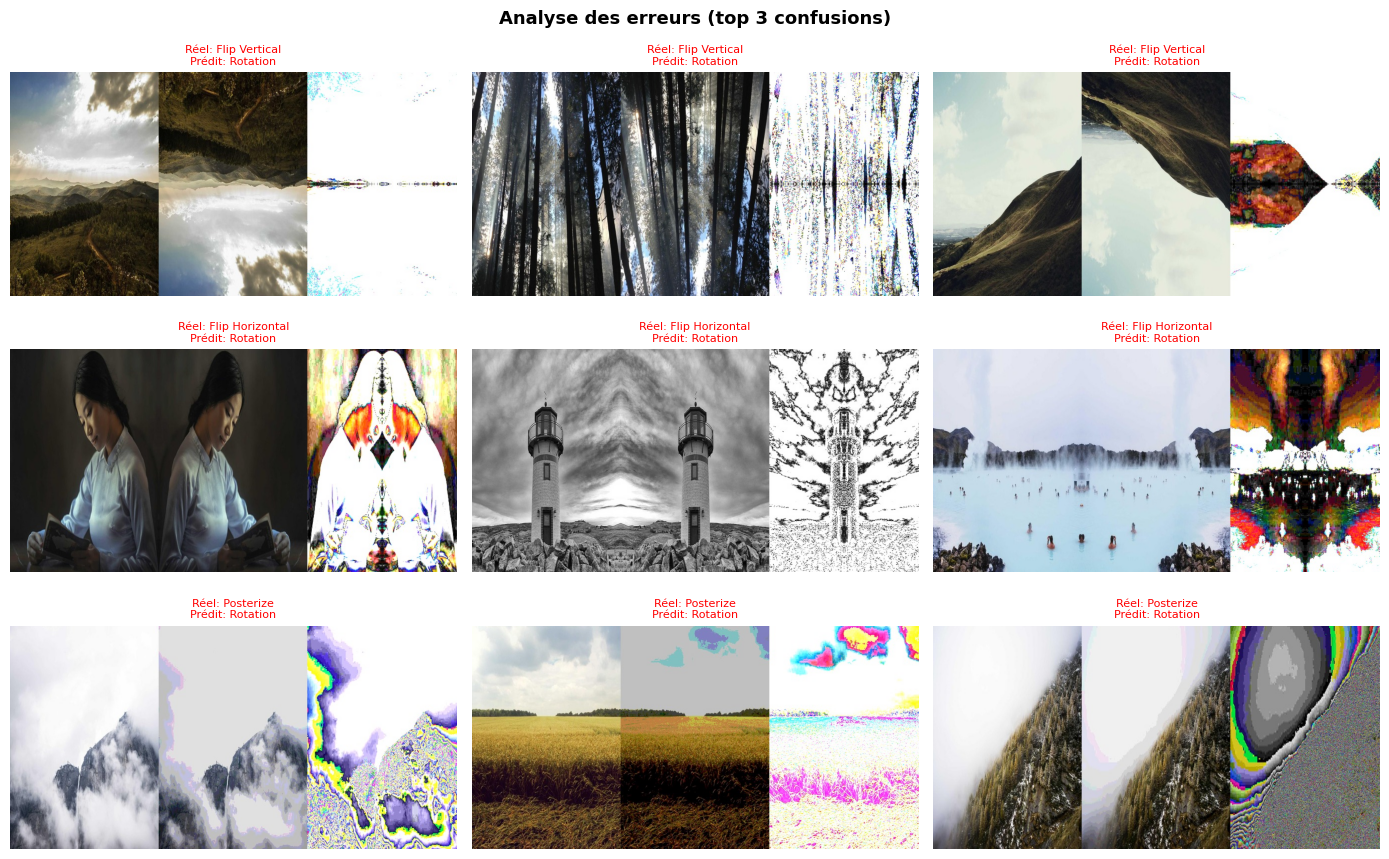

In [12]:
from collections import Counter

errors = [(rec, pred) for rec, pred, lbl in zip(val_records, preds, labels) if pred != lbl]
print(f"Total errors: {len(errors)} / {len(val_records)}")

error_pairs = Counter((rec["label"], pred) for rec, pred in errors)
print("\nTop 10 confusion pairs:")
for (true, pred), count in error_pairs.most_common(10):
    print(f"  {DISPLAY_NAMES.get(true, true):<25} -> {DISPLAY_NAMES.get(pred, pred):<25}  ({count}x)")

top_pairs = error_pairs.most_common(3)
fig, axes = plt.subplots(3, 3, figsize=(14, 9))

for row, ((true_cls, pred_cls), count) in enumerate(top_pairs):
    samples = [(rec, pred) for rec, pred in errors
               if rec["label"] == true_cls and pred == pred_cls][:3]
    for col, (rec, pred) in enumerate(samples):
        ax = axes[row][col]
        ax.imshow(Image.open(rec["image"]))
        ax.axis("off")
        ax.set_title(f"Réel: {DISPLAY_NAMES.get(true_cls, true_cls)}\nPrédit: {DISPLAY_NAMES.get(pred_cls, pred_cls)}",
                     fontsize=8, color="red")
    for col in range(len(samples), 3):
        axes[row][col].axis("off")

plt.suptitle("Analyse des erreurs (top 3 confusions)",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/output/error_analysis.jpeg", bbox_inches="tight", dpi=120)
plt.show()


In [13]:
metrics = {
    "accuracy":  round(acc, 4),
    "macro_f1":  round(macro_f1, 4),
    "n_val":     len(labels),
    "n_errors":  len(errors),
    "n_unknown": preds.count("unknown"),
    "per_class": {
        LABEL_SET_V3[i]: {
            "precision": round(float(precisions[i]), 4),
            "recall":    round(float(recalls[i]),    4),
            "f1":        round(float(f1s[i]),        4),
            "support":   int(labels.count(LABEL_SET_V3[i])),
        }
        for i in range(len(LABEL_SET_V3))
    },
    "top_confusions": [
        {"true": t, "pred": p, "count": c}
        for (t, p), c in error_pairs.most_common(10)
    ],
}

with open("/kaggle/working/output/eval_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("✅ Metrics saved")
print(json.dumps({k: v for k, v in metrics.items() if k != "per_class"}, indent=2))


✅ Metrics saved
{
  "accuracy": 0.5857,
  "macro_f1": 0.5825,
  "n_val": 560,
  "n_errors": 232,
  "n_unknown": 0,
  "top_confusions": [
    {
      "true": "flip_vertical",
      "pred": "rotation",
      "count": 19
    },
    {
      "true": "flip_horizontal",
      "pred": "rotation",
      "count": 12
    },
    {
      "true": "posterize",
      "pred": "rotation",
      "count": 11
    },
    {
      "true": "flip_vertical",
      "pred": "flip_horizontal",
      "count": 11
    },
    {
      "true": "colorize",
      "pred": "hue_saturation",
      "count": 10
    },
    {
      "true": "sharpen",
      "pred": "gaussian_blur",
      "count": 9
    },
    {
      "true": "brightness_contrast",
      "pred": "rotation",
      "count": 7
    },
    {
      "true": "invert",
      "pred": "rotation",
      "count": 7
    },
    {
      "true": "posterize",
      "pred": "flip_horizontal",
      "count": 7
    },
    {
      "true": "desaturate",
      "pred": "hue_saturation",
  

In [14]:
import shutil

shutil.make_archive(
    "/kaggle/working/output/qwen2vl-v4-lora-weights",
    "zip",
    "/kaggle/working/qwen2vl-v4-lora"
)
print("✅ Done — download from Output panel: qwen2vl-v4-lora-weights.zip")


✅ Done — download from Output panel: qwen2vl-v4-lora-weights.zip


In [15]:
import os

readme_path = "/kaggle/working/qwen2vl-v4-lora/README.md"

with open(readme_path, "w") as f:
    f.write("""---
base_model: Qwen/Qwen2-VL-2B-Instruct
license: apache-2.0
tags:
  - peft
  - lora
  - gimp
---
# AI2D V4 — Qwen2-VL-2B GIMP Classifier
Fine-tuned with QLoRA (r=64, 4-bit) on AI2D V4 dataset.
14 GIMP operation classes. Pipeline-unified triptych format.
""")
print("✅ README written")


✅ README written
